### Zadania

Celem listy jest zbadanie działania metod binaryzacji obrazów w skali szarości i kolorowych. Dążymy do wyobrębnienia obiektów znajdujących się na podanych obrazach, tzn. uzyskania separacji obiektów od tła, a także oddzielenia poszczególnych obiektów. Natomiast samo osiągnięcie "jakiegoś" wyniku ([`cv2.threshold`](https://docs.opencv.org/3.4/d7/d1b/group__imgproc__misc.html#gae8a4a146d1ca78c626a53577199e9c57) odpalone, próg wybrany "z palca", _coś tam_ wychodzi, wynik wyświetlony) to co najwyżej połowa sukcesu i oceny. Ważne jest przeprowadzenie eksperymentów wyjaśniających dobór parametrów.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [ ]:
%matplotlib inline
from ipywidgets import interact, interact_manual, IntSlider, Dropdown, Checkbox

##### Zad. 1: Monety szare

Dane są dwa czarno-białe obrazy monet, `monety_szare` oraz `monety_szare_szum`, z których drugi zawiera pewien poziom zakłóceń. Dokonaj binaryzacji tych obrazów za pomocą progowania.  
Jak wartość progu wpływa na wyniki?  
Jaki wpływ mają zakłócenia w drugim obrazie? Zastosuj wybraną metodę odszumiania i przeanalizuj efekty.

In [3]:
monety_szare = cv2.imread('Monety_szare.bmp')
monety_szum = cv2.imread('Monety_szare_szum.bmp')

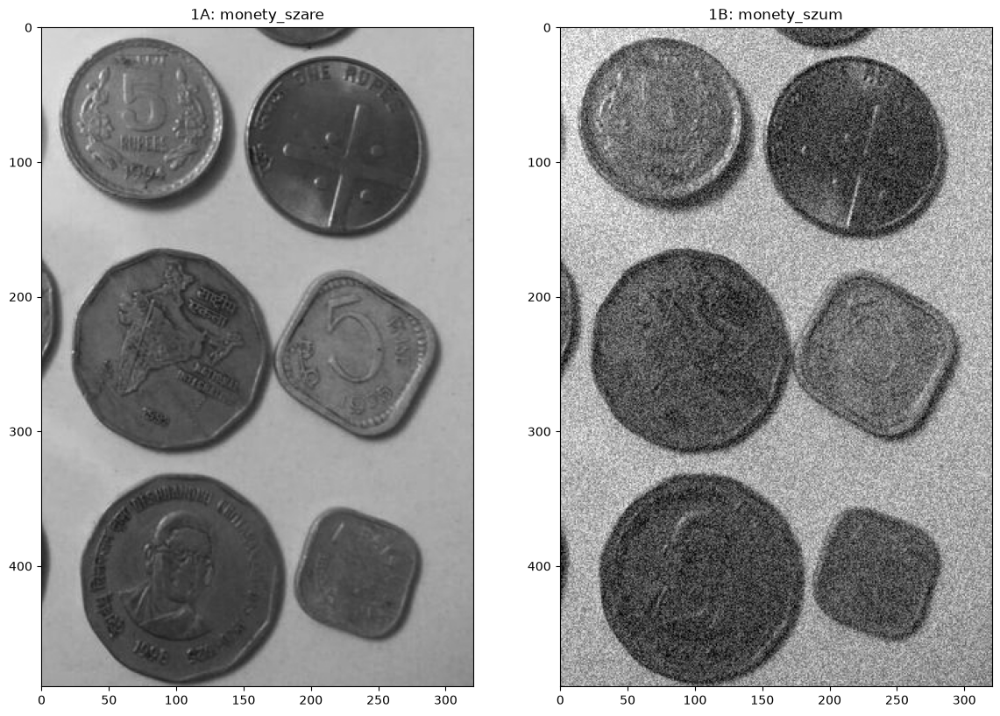

In [4]:
_, (a, b) = plt.subplots(1,2, figsize=(14,10))
a.imshow(monety_szare); a.title.set_text('1A: monety_szare')
b.imshow(monety_szum); b.title.set_text('1B: monety_szum')

In [ ]:
DARK_OBJECTS = True

def calc_histogram(image):
    hist = cv2.calcHist([image], [0], None, [256], [0, 256]).ravel()
    return hist

def show_histogram(image, T=None, axis=None, title='Histogram', color='black'):
    if axis is None:
        axis = plt.gca()
    axis.bar(np.arange(256), calc_histogram(image), width=1.0, color=color)
    if T is not None:
        axis.axvline(T, color='red', label=f'T = {T:.0f}')
        axis.legend()
    axis.set_title(title)
    axis.set_xlim(-10, 260)

def binarize_image(image, T, dark_objects=True):
    _, binary_image = cv2.threshold(image, T, 255, cv2.THRESH_BINARY_INV if dark_objects else cv2.THRESH_BINARY)
    return binary_image

def otsu_method(image):
    # Calculate histogram
    hist = calc_histogram(image)
    P = hist / hist.sum()  # Probability of each intensity level
    i = np.arange(256)  # Intensity levels
    mu_T = (P * i).sum()  # Total mean intensity
    sigma_T_squared = (P * ((i - mu_T) ** 2)).sum()  # Total variance
    best_t, best_sw = 0, np.inf
    for t in range(255):
        q1 = P[:t + 1].sum()  # Probability of class 1
        q2 = P[t + 1:].sum()  # Probability of class 2
        if q1 <= 0 or q2 <= 0:
            continue
        mu1 = (P[:t + 1] * i[:t + 1]).sum() / q1  # Mean of class 1
        mu2 = (P[t + 1:] * i[t + 1:]).sum() / q2  # Mean of class 2
        sigma1_squared = (P[:t + 1] * ((i[:t + 1] - mu1) ** 2)).sum() / q1  # Variance of class 1
        sigma2_squared = (P[t + 1:] * ((i[t + 1:] - mu2) ** 2)).sum() / q2  # Variance of class 2
        sw = q1 * sigma1_squared + q2 * sigma2_squared  # Within-class variance
        if sw < best_sw:
            best_sw = sw
            best_t = t
    sigma_b_squared = sigma_T_squared - best_sw  # Between-class variance
    eta = sigma_b_squared / sigma_T_squared if sigma_T_squared > 0 else 0.0  # Separability measure
    return best_t, eta

def denoise_image(image, method, k=3):
    if method == 'mean':
        return cv2.blur(image, (k, k))
    elif method == 'median':
        return cv2.medianBlur(image, k)
    elif method == 'gaussian':
        return cv2.GaussianBlur(image, (k, k), 0)
    else:
        return image

def iou(a, b):
    a, b = a>0, b>0
    return (a & b).sum() / max((a | b).sum(), 1)

def count_objects(binary_image, min_size=0):
    n, _, st, _ = cv2.connectedComponentsWithStats(binary_image)
    return int((st[1:, cv2.CC_STAT_AREA] >= min_size).sum())

def show_images(images, titles, columns=3, size=4):
    rows = int(np.ceil(len(images) / columns))
    fig, axis = plt.subplots(rows, columns, figsize=(size * columns, size * rows))
    axis = np.atleast_1d(axis).ravel()
    for ax_, im, t in zip(axis, images, titles):
        ax_.imshow(im, cmap='gray', vmin=0, vmax=255) # vmin/vmax: bez nich matplotlib sam "rozciąga" kontrast
        ax_.set_title(t, fontsize=10)
        ax_.axis('off')
    for ax_ in axis[len(images):]: # puste pola siatki wyłączamy
        ax_.axis('off')
    plt.tight_layout()
    plt.show()

Rozwiązanie części 1A:

In [10]:
gray_image = cv2.cvtColor(monety_szare, cv2.COLOR_BGR2GRAY)
gray_noise = cv2.cvtColor(monety_szum, cv2.COLOR_BGR2GRAY)

print('monety szare:')
print('shape:', gray_image.shape, '| type:', gray_image.dtype, '| min/max:', gray_image.min(), gray_image.max())
print('identical channels?', np.array_equal(monety_szare[..., 0], monety_szare[..., 1]))  # potwierdza, że to szary

print('\nmonety szum:')
print('shape:', gray_noise.shape, '| type:', gray_noise.dtype, '| min/max:', gray_noise.min(), gray_noise.max())
print('identical channels?', np.array_equal(monety_szum[..., 0], monety_szum[..., 1]))  # potwierdza, że to szary

monety szare:
shape: (490, 321) | type: uint8 | min/max: 19 254
identical channels? True

monety szum:
shape: (490, 321) | type: uint8 | min/max: 0 255
identical channels? True


cv2.threshold: T = 127
Otsu method: T = 127, eta = 0.86


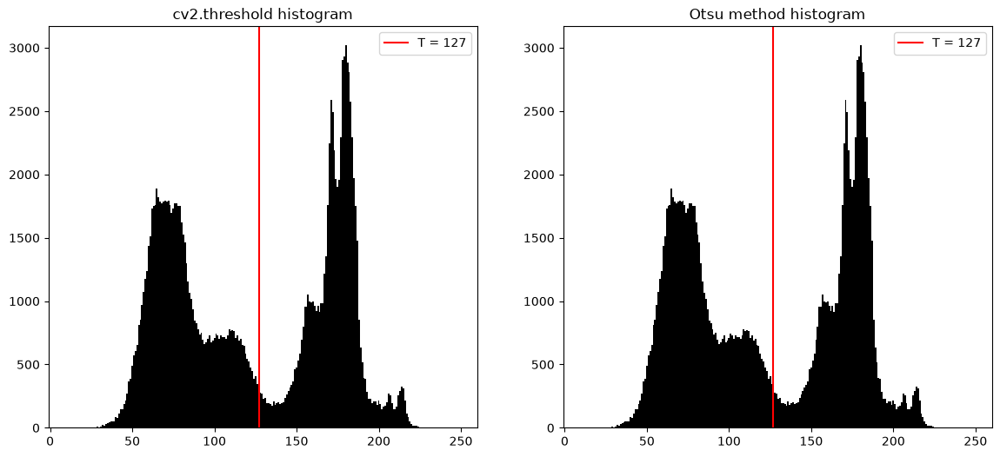

In [77]:
T_cv, _ = cv2.threshold(gray_image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
T_otsu, eta = otsu_method(gray_image)
print(f'cv2.threshold: T = {T_cv:.0f}')
print(f'Otsu method: T = {T_otsu:.0f}, eta = {eta:.2f}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
show_histogram(gray_image, T_cv, axis=ax1, title='cv2.threshold histogram')
show_histogram(gray_image, T_otsu, axis=ax2, title='Otsu method histogram')
plt.show()

In [ ]:
def treshold_exp(T=127):
    binary_image = binarize_image(gray_image, T) # binaryzacja progiem z suwaka
    fig, (a, b, c) = plt.subplots(1, 3, figsize=(15, 4))
    a.imshow(gray_image, cmap='gray', vmin=0, vmax=255); a.set_title('oryginał'); a.axis('off')
    show_histogram(gray_image, T, b)                            # histogram z linią progu
    c.imshow(binary_image, cmap='gray', vmin=0, vmax=255); c.axis('off')
    # % białych = pole obiektów; liczba obiektów (ignorujemy plamki < 50 px; dostosuj do rozdzielczości)
    c.set_title(f'T={T} | białe: {(binary_image > 0).mean() * 100:.1f}% | obiekty: {count_objects(binary_image, 50)}')
    plt.show()

interact(treshold_exp, T=IntSlider(min=0, max=255, step=1, value=127, continuous_update=False));
# Przesuwaj suwak: obserwuj, w którym momencie monety "wyłaniają się", a w którym zlewają z tłem.
# Wartości, które moim zdaniem warto pokazać: T ~ 50 (za niski), T_otsu (dobry), T ~ 200 (za wysoki)

interactive(children=(IntSlider(value=127, continuous_update=False, description='T', max=255), Output()), _dom…

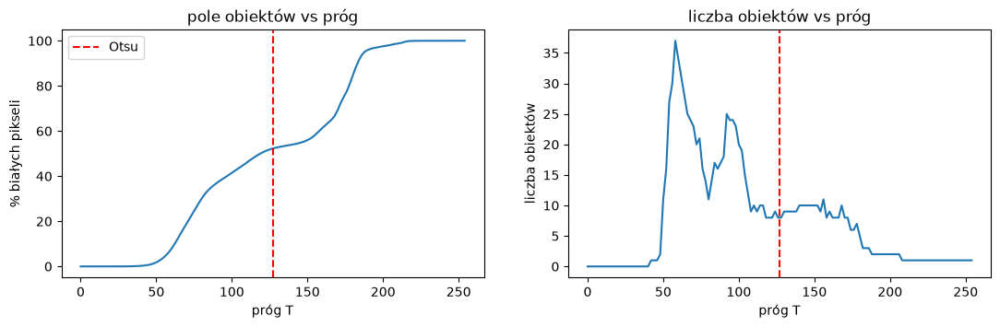

In [16]:
threshold_values = np.arange(0, 256, 2)
white = [(binarize_image(gray_image, T) > 0).mean() * 100 for T in threshold_values]
n_objects = [count_objects(binarize_image(gray_image, T), 50) for T in threshold_values]
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 3.5))
a.plot(threshold_values, white); a.axvline(T_cv, color='red', ls='--', label='Otsu'); a.legend()
a.set_xlabel('próg T'); a.set_ylabel('% białych pikseli'); a.set_title('pole obiektów vs próg')
b.plot(threshold_values, n_objects); b.axvline(T_cv, color='red', ls='--')
b.set_xlabel('próg T'); b.set_ylabel('liczba obiektów'); b.set_title('liczba obiektów vs próg')
plt.show()

Rozwiązanie części 1B:


czysty      std=49.9 | % pikseli =0: 0.00 | % pikseli =255: 0.00
zaszumiony  std=56.3 | % pikseli =0: 0.13 | % pikseli =255: 0.16


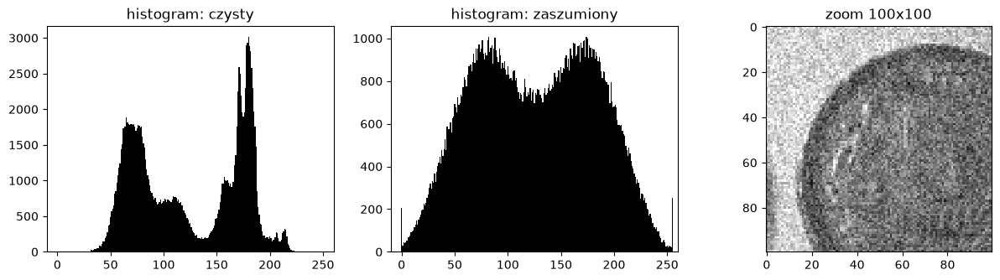

In [80]:
for name, im in [('czysty', gray_image), ('zaszumiony', gray_noise)]:
    print(f'{name:11s} std={im.std():.1f} | % pikseli =0: {(im == 0).mean() * 100:.2f} | % pikseli =255: {(im == 255).mean() * 100:.2f}')
# Dużo pikseli dokładnie 0 i 255 => szum impulsowy (sól i pieprz) => mediana. Brak => raczej gaussowski => Gauss/średnia.
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
show_histogram(gray_image, axis=ax[0], title='histogram: czysty')
show_histogram(gray_noise, axis=ax[1], title='histogram: zaszumiony')   # szum rozlewa piki i zmniejsza dolinę między nimi
ax[2].imshow(gray_noise[:100, :100], cmap='gray', vmin=0, vmax=255, interpolation='nearest')  # zoom na fragment: widać ziarno
ax[2].set_title('zoom 100x100'); plt.show()

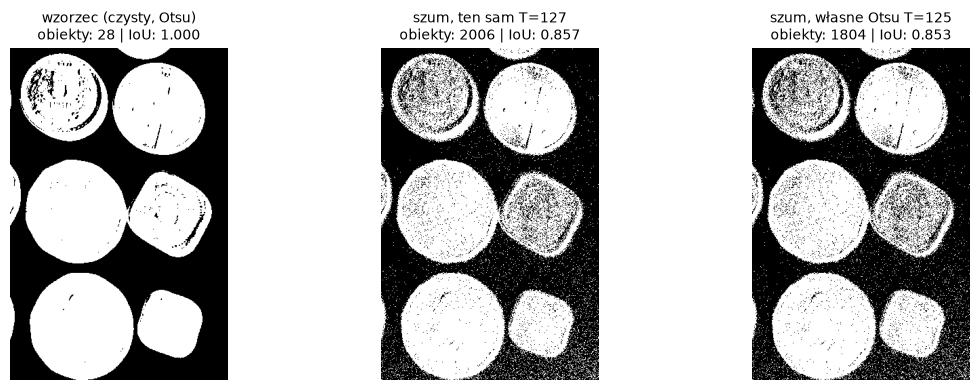

In [19]:
assert gray_image.shape == gray_noise.shape, 'obrazy mają różne rozmiary, IoU nie ma sensu'
ref = binarize_image(gray_image, T_cv)          # maska z CZYSTEGO obrazu = nasz "wzorzec"
T_szum, _ = cv2.threshold(gray_noise, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)   # Otsu na zaszumionym
warianty = {
    'wzorzec (czysty, Otsu)': ref,
    f'szum, ten sam T={T_cv:.0f}': binarize_image(gray_noise, T_cv),
    f'szum, własne Otsu T={T_szum:.0f}': binarize_image(gray_noise, T_szum),
}
show_images(list(warianty.values()),
      [f'{n}\nobiekty: {count_objects(bw)} | IoU: {iou(bw, ref):.3f}' for n, bw in warianty.items()])
# Spodziewam się setek/tysięcy drobnych "kropek" (fałszywych obiektów) i IoU wyraźnie < 1.

metoda     k  T(Otsu)    IoU  obiekty
mean       1      125  0.853     1804
mean       3      127  0.963       38
mean       5      128  0.967       12
mean       7      128  0.964       10
mean       9      128  0.959        9
mean      11      128  0.953        9
mean      15      129  0.938        6
gaussian   1      125  0.853     1804
gaussian   3      127  0.960       49
gaussian   5      127  0.968       14
gaussian   7      128  0.970       10
gaussian   9      128  0.969       11
gaussian  11      128  0.967       10
gaussian  15      128  0.963        8
median     1      125  0.853     1804
median     3      127  0.952       92
median     5      128  0.965       19
median     7      128  0.966       12
median     9      128  0.965       12
median    11      128  0.962       10
median    15      129  0.951        8


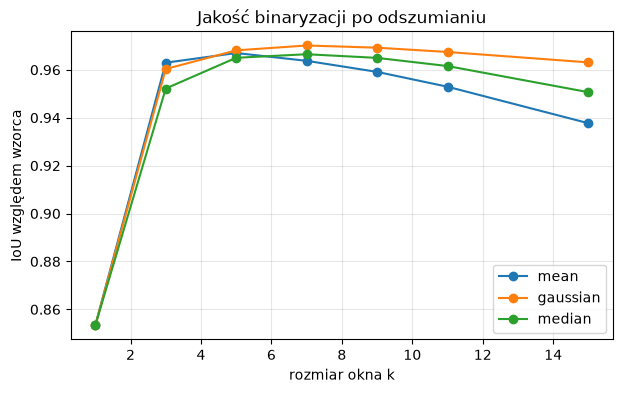

In [21]:
ks = [1, 3, 5, 7, 9, 11, 15]                           # k=1 oznacza brak filtracji (punkt odniesienia)
method = ['mean', 'gaussian', 'median']
results = {m: [] for m in method}
print(f"{'metoda':8s} {'k':>3s} {'T(Otsu)':>8s} {'IoU':>6s} {'obiekty':>8s}")
for m in method:
    for k in ks:
        f = denoise_image(gray_noise, m, k)                          # 1) odszum
        T, _ = cv2.threshold(f, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)  # 2) Otsu liczone NA NOWO (histogram się zmienił)
        bi = binarize_image(f, T)            # 3) binaryzacja
        results[m].append(iou(bi, ref))                  # jakość = zgodność ze wzorcem
        print(f'{m:8s} {k:3d} {T:8.0f} {results[m][-1]:6.3f} {count_objects(bi):8d}')
plt.figure(figsize=(7, 4))
for m in method:
    plt.plot(ks, results[m], marker='o', label=m)
plt.xlabel('rozmiar okna k'); plt.ylabel('IoU względem wzorca'); plt.legend(); plt.grid(alpha=.3)
plt.title('Jakość binaryzacji po odszumianiu'); plt.show()
# Czytaj: krzywa rośnie (szum znika), potem ewentualnie spada (nadmierne rozmycie psuje kształt/krawędzie).
# Wartości, które moim zdaniem warto pokazać: mediana k=3 i k=5, Gauss k=5, średnia k=5, oraz jedno za duże k (np. 15)

In [87]:
def denoise_preview(method='mean', k=3, T=127, use_otsu=True):
    f = denoise_image(gray_noise, method, k)                         # odszumiony obraz
    if use_otsu:
        T, _ = cv2.threshold(f, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    bw = binarize_image(f, T)
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].imshow(f, cmap='gray', vmin=0, vmax=255); ax[0].set_title(f'{method}, k={k}'); ax[0].axis('off')
    show_histogram(f, T, ax[1], 'histogram po odszumieniu')   # zwróć uwagę, jak piki się "zaostrzają"
    ax[2].imshow(bw, cmap='gray', vmin=0, vmax=255); ax[2].axis('off')
    ax[2].set_title(f'T={T:.0f} | IoU={iou(bw, ref):.3f} | obiekty={count_objects(bw)}')
    plt.show()

interact(denoise_preview,
         method=Dropdown(options=['mean', 'gaussian', 'median'], value='median'),
         k=IntSlider(min=1, max=21, step=2, value=3, continuous_update=False),   # tylko nieparzyste
         T=IntSlider(min=0, max=255, value=127, continuous_update=False),
         use_otsu=Checkbox(value=True));

interactive(children=(Dropdown(description='method', index=2, options=('mean', 'gaussian', 'median'), value='m…

##### Zad. 2: Monety kolorowe

Na podobnej zasadzie dokonaj binaryzacji poniższego obrazu kolorowego.  
Skorzystaj z modelu barw HSV. Uzasadnij dobór kanału oraz progu binaryzacji.

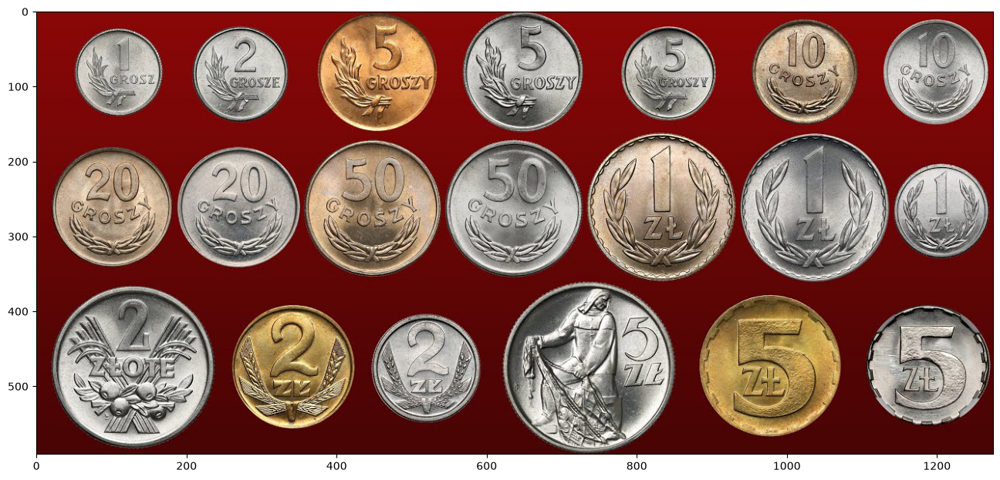

In [28]:
monety_kolor = cv2.imread('Monety_kolor.bmp')
plt.subplots(1,1,figsize=(16,8))[1].imshow(monety_kolor[..., ::-1]);

H: min/max = 0 179 | S: min/max = 0 255 | V: min/max = 0 255


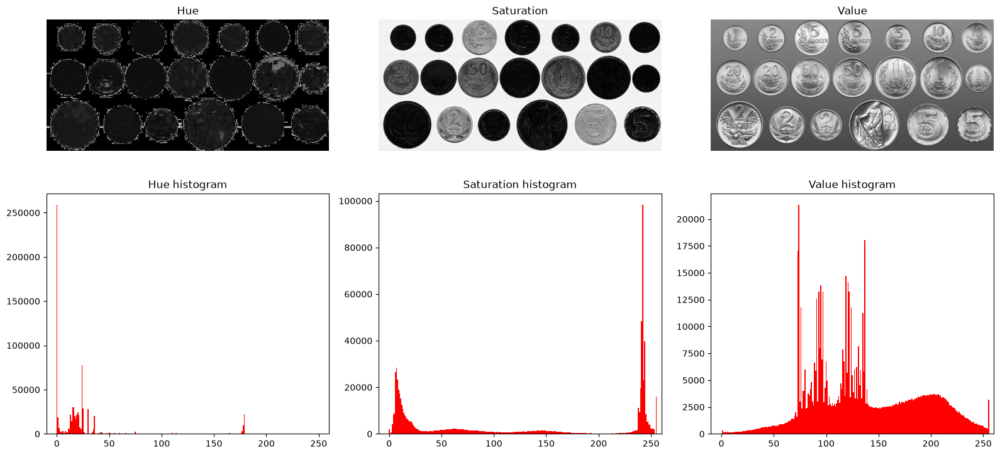

In [85]:
hsv_image = cv2.cvtColor(monety_kolor, cv2.COLOR_BGR2HSV)
H, S, V = cv2.split(hsv_image) # 3 obrazy jednokanałowe
print('H: min/max =', H.min(), H.max(), '| S: min/max =', S.min(), S.max(), '| V: min/max =', V.min(), V.max())

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for i, (name, channel) in enumerate([('Hue', H), ('Saturation', S), ('Value', V)]):
    ax[0, i].imshow(channel, cmap='gray', vmin=0, vmax=255); ax[0, i].set_title(name); ax[0, i].axis('off')
    show_histogram(channel, axis=ax[1, i], title=f'{name} histogram', color='red')
# ax[1, 0].axis('off')
ax[0, 0].axis('off'); plt.tight_layout(); plt.show()


kanał   T(Otsu)    eta    T(CV)
H            92   0.87       92
S           131   0.90      131
V           148   0.73      148
B            88   0.82       88
G            90   0.85       90
R           148   0.73      148
gray        108   0.84      108


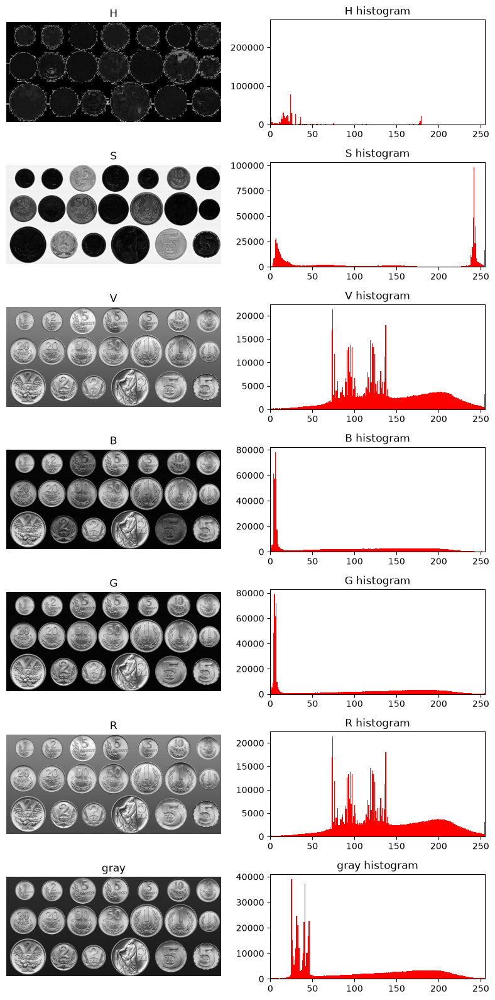

In [63]:
channels = {'H': H, 'S': S, 'V': V, 'B': monety_kolor[..., 0], 'G': monety_kolor[..., 1], 'R': monety_kolor[..., 2], 'gray': cv2.cvtColor(monety_kolor, cv2.COLOR_BGR2GRAY)}
print(f"{'kanał':6s} {'T(Otsu)':>8s} {'eta':>6s} {'T(CV)':>8s}")
for name, channel in channels.items():
    T, eta = otsu_method(channel)
    T_cv, _ = cv2.threshold(channel, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    print(f'{name:6s} {T:8.0f} {eta:6.2f} {T_cv:8.0f}')

# show plot with histograms for each channel
fig, ax = plt.subplots(7, 2, figsize=(8, 16))
for i, (name, channel) in enumerate(channels.items()):
    ax[i, 0].imshow(channel, cmap='gray', vmin=0, vmax=255); ax[i, 0].set_title(name); ax[i, 0].axis('off')
    show_histogram(channel, axis=ax[i, 1], title=f'{name} histogram', color='red')
plt.tight_layout(); plt.show()

In [ ]:
# i need to calculate eta for each T for S channel and save it as dict
etas = {}
for T in range(0, 256):
    

In [66]:
def hsv_preview(channel='S', T=100, inv=False, use_otsu=False):
    c = {'H': H, 'S': S, 'V': V, 'B': monety_kolor[..., 0], 'G': monety_kolor[..., 1], 'R': monety_kolor[..., 2], 'gray': cv2.cvtColor(monety_kolor, cv2.COLOR_BGR2GRAY)}[channel]
    if use_otsu:
        T_, _ = cv2.threshold(c, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    else:
        T_ = T
    _, bi_image = cv2.threshold(c, T_, 255, cv2.THRESH_BINARY_INV if inv else cv2.THRESH_BINARY)
    cut_out = cv2.bitwise_and(monety_kolor, monety_kolor, mask=bi_image)
    fig, ax = plt.subplots(1, 4, figsize=(18, 4))
    ax[0].imshow(c, cmap='gray', vmin=0, vmax=255); ax[0].set_title(f'kanał {channel}'); ax[0].axis('off')
    show_histogram(c, T_, ax[1], f'histogram {channel}')
    ax[2].imshow(bi_image, cmap='gray', vmin=0, vmax=255); ax[2].axis('off')
    ax[2].set_title(f'maska | obiekty: {count_objects(bi_image, 100)}')
    ax[3].imshow(cut_out[..., ::-1]); ax[3].set_title('wycięte monety'); ax[3].axis('off')
    plt.show()

interact(hsv_preview, channel=Dropdown(options=['H', 'S', 'V', 'B', 'G', 'R', 'gray'], value='S'), T=IntSlider(min=0, max=255, value=100, continuous_update=False), inv=Checkbox(value=False), use_otsu=Checkbox(value=False));

interactive(children=(Dropdown(description='channel', index=1, options=('H', 'S', 'V', 'B', 'G', 'R', 'gray'),…

Przetestuj opracowany powyżej algorytm na poniższym obrazie z wyraźnym zaszumieniem. Co się zmienia i dlaczego? Uzupełnij potok przetwarzania o odszumianie.

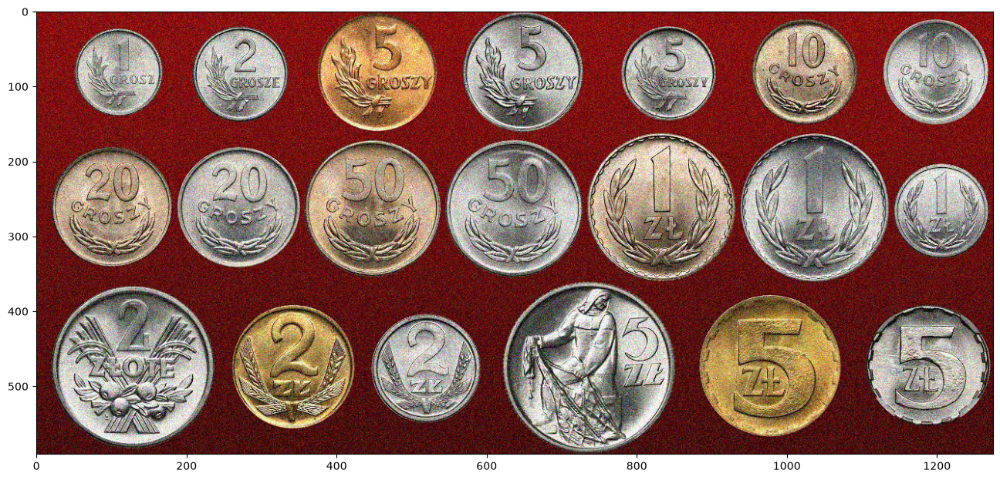

In [67]:
monety_kolor_szum = cv2.imread('Monety_kolor_szum.bmp')
plt.subplots(1,1,figsize=(16,8))[1].imshow(monety_kolor_szum[..., ::-1]);

H: min/max = 0 179 | S: min/max = 0 255 | V: min/max = 0 255


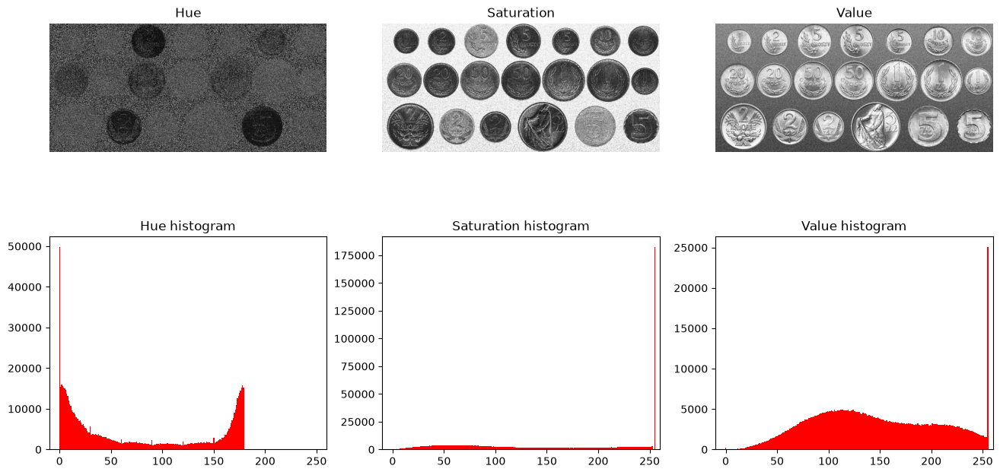

In [83]:
hsv_noise = cv2.cvtColor(monety_kolor_szum, cv2.COLOR_BGR2HSV)
H_noise, S_noise, V_noise = cv2.split(hsv_noise)
print('H: min/max =', H_noise.min(), H_noise.max(), '| S: min/max =', S_noise.min(), S_noise.max(), '| V: min/max =', V_noise.min(), V_noise.max())

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for i, (name, channel) in enumerate([('Hue', H_noise), ('Saturation', S_noise), ('Value', V_noise)]):
    ax[0, i].imshow(channel, cmap='gray', vmin=0, vmax=255); ax[0, i].set_title(name); ax[0, i].axis('off')
    show_histogram(channel, axis=ax[1, i], title=f'{name} histogram', color='red')



kanał   T(Otsu)    eta    T(CV)
H            89   0.88       89
S           153   0.85      153
V           152   0.72      152
B            96   0.80       96
G            99   0.82       99
R           143   0.69      143
gray        113   0.82      113


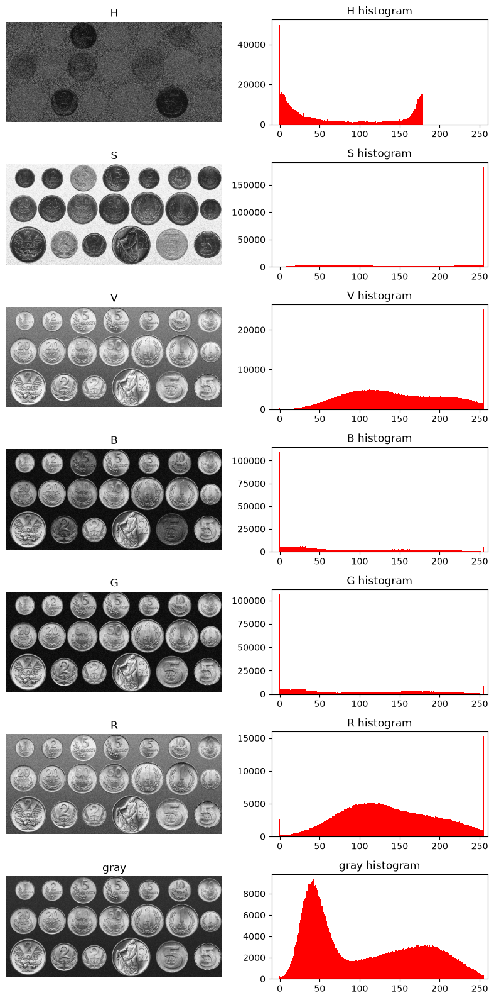

In [84]:
print(f"{'kanał':6s} {'T(Otsu)':>8s} {'eta':>6s} {'T(CV)':>8s}")
for name, channel in [('H', H_noise), ('S', S_noise), ('V', V_noise), ('B', monety_kolor_szum[..., 0]), ('G', monety_kolor_szum[..., 1]), ('R', monety_kolor_szum[..., 2]), ('gray', cv2.cvtColor(monety_kolor_szum, cv2.COLOR_BGR2GRAY))]:
    T, eta = otsu_method(channel)
    T_cv, _ = cv2.threshold(channel, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    print(f'{name:6s} {T:8.0f} {eta:6.2f} {T_cv:8.0f}')

fig, ax = plt.subplots(7, 2, figsize=(8, 16))
for i, (name, channel) in enumerate([('H', H_noise), ('S', S_noise), ('V', V_noise), ('B', monety_kolor_szum[..., 0]), ('G', monety_kolor_szum[..., 1]), ('R', monety_kolor_szum[..., 2]), ('gray', cv2.cvtColor(monety_kolor_szum, cv2.COLOR_BGR2GRAY))]):
    ax[i, 0].imshow(channel, cmap='gray', vmin=0, vmax=255); ax[i, 0].set_title(name); ax[i, 0].axis('off')
    show_histogram(channel, axis=ax[i, 1], title=f'{name} histogram', color='red')
plt.tight_layout(); plt.show()

In [75]:
def hsv_preview_noise(channel='S', T=100, inv=False, use_otsu=False):
    c = {'H': H_noise, 'S': S_noise, 'V': V_noise, 'B': monety_kolor_szum[..., 0], 'G': monety_kolor_szum[..., 1], 'R': monety_kolor_szum[..., 2], 'gray': cv2.cvtColor(monety_kolor_szum, cv2.COLOR_BGR2GRAY)}[channel]
    if use_otsu:
        T_, _ = cv2.threshold(c, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    else:
        T_ = T
    _, bi_image = cv2.threshold(c, T_, 255, cv2.THRESH_BINARY_INV if inv else cv2.THRESH_BINARY)
    cut_out = cv2.bitwise_and(monety_kolor, monety_kolor, mask=bi_image)
    fig, ax = plt.subplots(1, 4, figsize=(18, 4))
    ax[0].imshow(c, cmap='gray', vmin=0, vmax=255); ax[0].set_title(f'kanał {channel}'); ax[0].axis('off')
    show_histogram(c, T_, ax[1], f'histogram {channel}')
    ax[2].imshow(bi_image, cmap='gray', vmin=0, vmax=255); ax[2].axis('off')
    ax[2].set_title(f'maska | obiekty: {count_objects(bi_image, 100)}')
    ax[3].imshow(cut_out[..., ::-1]); ax[3].set_title('wycięte monety'); ax[3].axis('off')
    plt.show()

interact(hsv_preview_noise, channel=Dropdown(options=['H', 'S', 'V', 'B', 'G', 'R', 'gray'], value='S'), T=IntSlider(min=0, max=255, value=100, continuous_update=False), inv=Checkbox(value=False), use_otsu=Checkbox(value=False));

interactive(children=(Dropdown(description='channel', index=1, options=('H', 'S', 'V', 'B', 'G', 'R', 'gray'),…

In [88]:
def segmentuj_S(bgr, metoda='mean', k=5, gdzie='przed'):
    if gdzie == 'przed':
        bgr = denoise_image(bgr, metoda, k)                     # filtracja każdego kanału B,G,R osobno -> potem HSV
    S_ = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)[..., 1]    # kanał nasycenia
    if gdzie == 'po':
        S_ = denoise_image(S_, metoda, k)                       # filtracja już samego kanału S
    T, bw = cv2.threshold(S_, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return S_, T, bw

ref_k = segmentuj_S(monety_kolor, 'mean', 1)[2]       # wzorzec: obraz czysty (k=1 = bez filtra)
print(f"{'gdzie':6s} {'metoda':8s} {'k':>3s} {'IoU':>6s} {'eta(S)':>7s}")
for gdzie in ['przed', 'po']:
    for m in ['mean', 'gaussian', 'median']:
        for k in [3, 5, 7, 9]:
            S_, T, bw = segmentuj_S(monety_kolor_szum, m, k, gdzie)
            print(f'{gdzie:6s} {m:8s} {k:3d} {iou(bw, ref_k):6.3f} {otsu_method(S_)[1]:7.3f}')
# Warto pokazać: najlepszą konfigurację, jedną "przeciętną" i jedną z za dużym k.

gdzie  metoda     k    IoU  eta(S)
przed  mean       3  0.929   0.888
przed  mean       5  0.930   0.890
przed  mean       7  0.926   0.886
przed  mean       9  0.921   0.880
przed  gaussian   3  0.929   0.886
przed  gaussian   5  0.935   0.891
przed  gaussian   7  0.933   0.891
przed  gaussian   9  0.931   0.890
przed  median     3  0.910   0.877
przed  median     5  0.925   0.886
przed  median     7  0.925   0.888
przed  median     9  0.919   0.888
po     mean       3  0.880   0.867
po     mean       5  0.874   0.870
po     mean       7  0.871   0.868
po     mean       9  0.868   0.864
po     gaussian   3  0.886   0.868
po     gaussian   5  0.882   0.870
po     gaussian   7  0.877   0.871
po     gaussian   9  0.876   0.871
po     median     3  0.874   0.887
po     median     5  0.864   0.897
po     median     7  0.859   0.900
po     median     9  0.855   0.900


In [ ]:
def podglad_pipeline(metoda='mean', k=5, gdzie='przed'):
    S_, T, bw = segmentuj_S(monety_kolor_szum, metoda, k, gdzie)
    wyc = cv2.bitwise_and(monety_kolor_szum, monety_kolor_szum, mask=bw)
    fig, ax = plt.subplots(1, 4, figsize=(18, 4))
    ax[0].imshow(S_, cmap='gray', vmin=0, vmax=255); ax[0].set_title('S po odszumieniu'); ax[0].axis('off')
    show_histogram(S_, T, ax[1], 'histogram S')
    ax[2].imshow(bw, cmap='gray'); ax[2].axis('off'); ax[2].set_title(f'IoU={iou(bw, ref_k):.3f}')
    ax[3].imshow(wyc[..., ::-1]); ax[3].axis('off'); plt.show()

interact(podglad_pipeline, metoda=Dropdown(options=['mean', 'gaussian', 'median'], value='mean'),
         k=IntSlider(min=1, max=15, step=2, value=5, continuous_update=False),
         gdzie=Dropdown(options=['przed', 'po'], value='przed'));

interactive(children=(Dropdown(description='metoda', options=('mean', 'gaussian', 'median'), value='mean'), In…

##### Zad. 3: Tekst

W tym przypadku należy wyodrębnić litery od bardzo nierównomiernie oświetlonego tła. Skorzystaj z binaryzacji metodą Otsu. Zastosuj binaryzację w sposób lokalny (oknem przesuwnym). Jaki wpływ ma rozmiar okna na jakość binaryzacji? Jak przesuwać okno?

_(Pełna punktacja za zadanie wymaga własnoręcznej implementacji okna przesuwnego - samo Otsu możesz wziąć z OpenCV. Użycie zamiast tego_ `cv2.adaptiveThreshold` _liczone będzie jako pół zadania, ale jedynie po demonstracji zrozumienia tej metody.)_

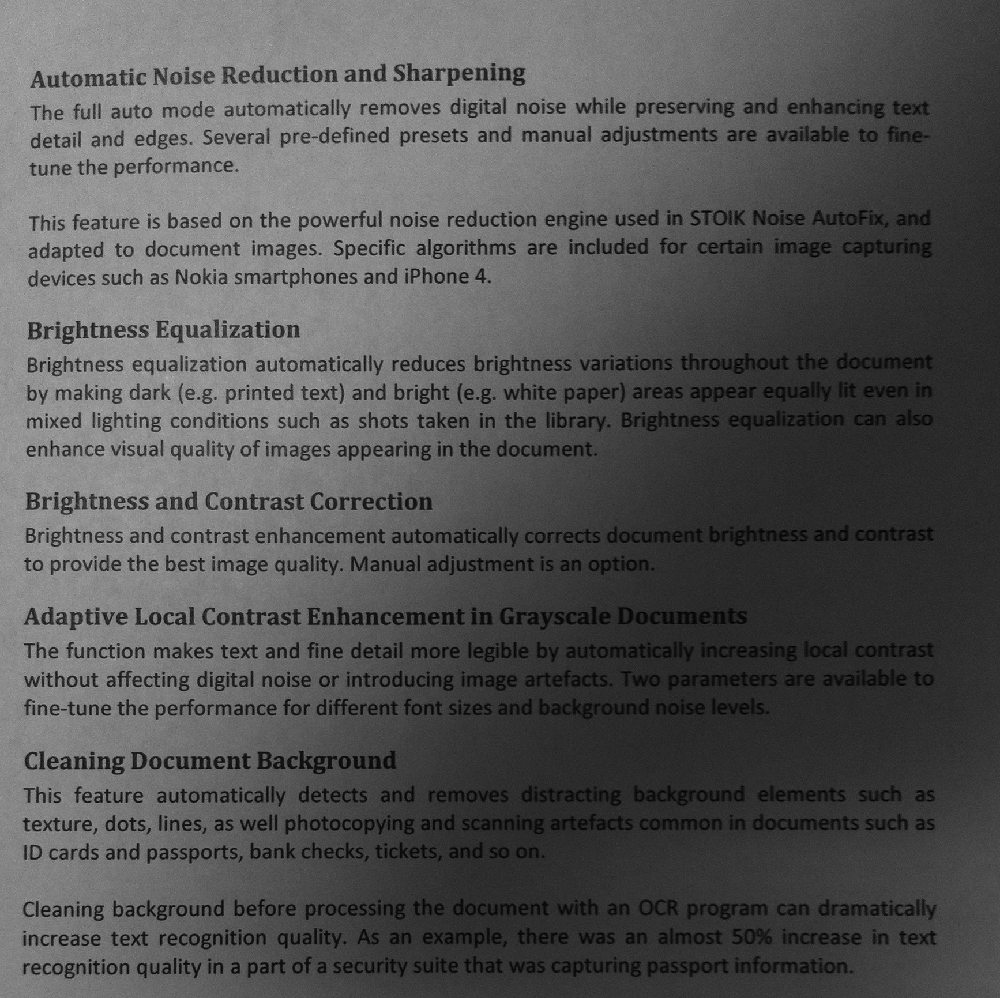

In [90]:
tekst = cv2.imread('Tekst1.bmp')
Image.fromarray(cv2.cvtColor(tekst, cv2.COLOR_BGR2GRAY))

Rozwiązanie:

In [105]:
tekst.shape

(1731, 1734, 3)

In [106]:
import time
def otsu_local(image, window_size, step):
    assert 1 <= step <= window_size, 'Must have 1 <= step <= window_size'
    height, width = image.shape
    votes = np.zeros((height, width), dtype=np.uint32)
    counts = np.zeros((height, width), dtype=np.uint32)

    for y in range(0, height, step):
        for x in range(0, width, step):
            y_end = min(y + window_size, height)
            x_end = min(x + window_size, width)

            window = image[y:y_end, x:x_end]

            threshold, _ = cv2.threshold(
                window, 0, 255,
                cv2.THRESH_BINARY + cv2.THRESH_OTSU
            )

            local_binary = (window > threshold).astype(np.uint32)

            votes[y:y_end, x:x_end] += local_binary
            counts[y:y_end, x:x_end] += 1

    binary = np.where(
        votes * 2 >= counts, 255, 0
    ).astype(np.uint8)

    return binary

def otsu_local(image, window_size, step, contrast=10):
    assert 1 <= step <= window_size, 'Must have 1 <= step <= window_size'
    height, width = image.shape
    votes = np.zeros((height, width), dtype=np.uint32)
    counts = np.zeros((height, width), dtype=np.uint32)

    for y in range(0, height, step):
        for x in range(0, width, step):
            y_end = min(y + window_size, height)
            x_end = min(x + window_size, width)

            window = image[y:y_end, x:x_end]

            p10, p90 = np.percentile(window, [10, 90])
            contr = p90 - p10
            if contr < contrast:
                local_binary = np.ones(window.shape, dtype=np.uint32)
            else:
                threshold, _ = cv2.threshold(
                    window, 0, 255,
                    cv2.THRESH_BINARY + cv2.THRESH_OTSU
                )
                local_binary = (window > threshold).astype(np.uint32)

            votes[y:y_end, x:x_end] += local_binary
            counts[y:y_end, x:x_end] += 1

    binary = np.where(
        votes * 2 >= counts, 255, 0
    ).astype(np.uint8)

    return binary

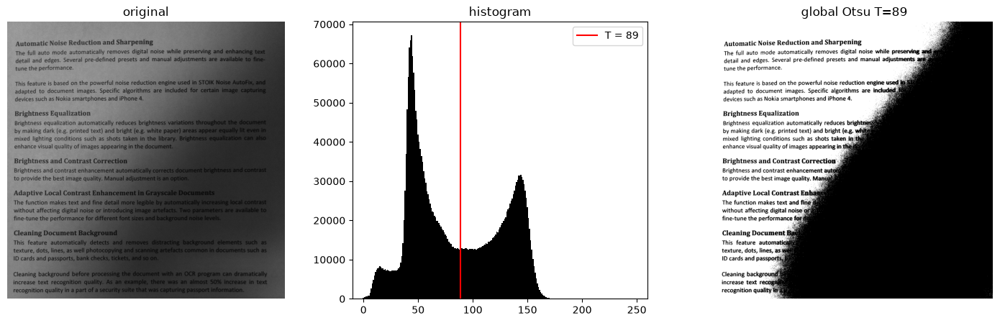

In [107]:
tekst_szary = cv2.cvtColor(tekst, cv2.COLOR_BGR2GRAY)

T_gt, bw_gt = cv2.threshold(tekst_szary, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

ax[0].imshow(tekst_szary, cmap='gray', vmin=0, vmax=255)
ax[0].set_title('original')
ax[0].axis('off')

show_histogram(
    tekst_szary, T_gt, ax[1],
    'histogram'
)

ax[2].imshow(bw_gt, cmap='gray')
ax[2].set_title(f'global Otsu T={T_gt:.0f}')
ax[2].axis('off')

plt.show()

In [108]:
def preview_local_otsu(w=51, step=13, contrast=20):
    t0 = time.perf_counter()

    bw = otsu_local(tekst_szary, w, step, contrast)

    dt = time.perf_counter() - t0

    plt.figure(figsize=(10, 6))
    plt.imshow(bw, cmap='gray')
    plt.axis('off')

    plt.title(
        f'local Otsu: w={w}, step={step}, '
        f'contrast={contrast} | {dt:.1f}s'
    )

    plt.show()


interact_manual(
    preview_local_otsu,
    w=IntSlider(min=5, max=251, step=2, value=51),
    step=IntSlider(min=1, max=101, value=13),
    contrast=IntSlider(min=0, max=80, value=20)
)

interactive(children=(IntSlider(value=51, description='w', max=251, min=5, step=2), IntSlider(value=13, descri…

<function __main__.preview_local_otsu(w=51, step=13, contrast=20)>

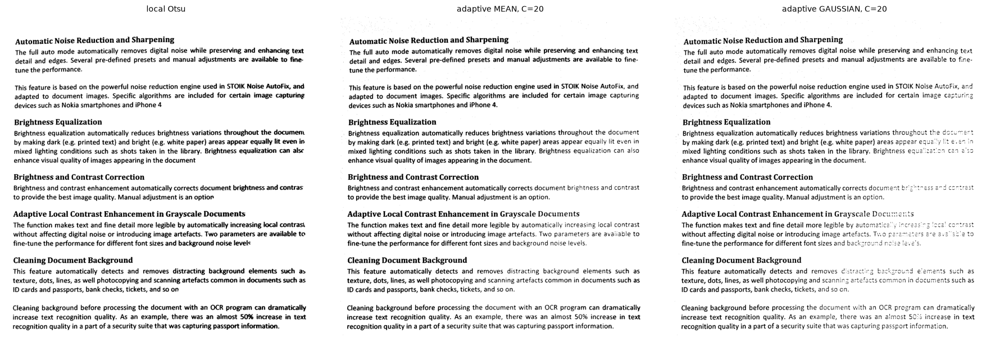

In [ ]:
w = 61

ad_mean = cv2.adaptiveThreshold(
    tekst_szary, 255,
    cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY,
    w, 20
)

ad_gauss = cv2.adaptiveThreshold(
    tekst_szary, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    w, 20
)

l_otsu = otsu_local(tekst_szary, w, 13, 20)

show_images(
    [l_otsu, ad_mean, ad_gauss],
    [
        'local Otsu',
        'adaptive MEAN, C=20',
        'adaptive GAUSSIAN, C=20'
    ],
    columns=3,
    size=6
)